# Phase 1 lab report: invoice extraction benchmark

Six models extract six fields from 30 labeled invoices, three times each. This notebook turns
the benchmark's raw files (`runs/*/calls.jsonl` and `runs/*/predictions.jsonl`) into the
tables and charts behind the Phase 1 guide.

Regenerate it from a clean kernel with `uv run poe report`. Figures are also written to
`figures/` as SVG for the guide.

In [1]:
import pandas as pd
from IPython.display import display

from p01 import analysis, figures
from p01.run import RESULTS
from p01.schema import load_cases

%config InlineBackend.figure_formats = ["png"]
%config InlineBackend.rc = {"figure.dpi": 120}
figures.apply_style()
pd.set_option("display.max_rows", 200)

FIGURES = RESULTS.parent / "figures"
RUN_LABELS = {
    "20261112-053218": "1 · baseline",
    "20261112-054542": "2 · spec clarified",
    "20261112-055405": "3 · hardware fixed",
}
cases = load_cases()
run_dirs = sorted(path for path in RESULTS.iterdir() if path.is_dir())
frames = {run.name: analysis.per_prediction(run) for run in run_dirs}
summaries = {run_id: analysis.summarize(frame) for run_id, frame in frames.items()}
final_id = run_dirs[-1].name
final, final_summary = frames[final_id], summaries[final_id]
print(f"{len(run_dirs)} runs; latest: {final_id} ({len(final)} predictions)")

3 runs; latest: 20261112-055405 (540 predictions)


## Summary of the latest run

`exact` is the share of predictions with all six fields correct; `low`–`high` is its 95% Wilson
interval with the 30 *cases* as the sample size, because repeats of a case are not independent.
`all 3` and `any of 3` are the share of cases a model got right in every repeat, and in at
least one. Costs are per 1,000 extractions, including any repair calls.

In [2]:
def as_table(summary: pd.DataFrame) -> pd.DataFrame:
    percent = "{:.1%}".format
    return pd.DataFrame(
        {
            "exact": summary.exact_rate.map(percent),
            "low": summary.ci_low.map(percent),
            "high": summary.ci_high.map(percent),
            "all 3": summary.all_repeats_correct.map(percent),
            "any of 3": summary.any_repeat_correct.map(percent),
            "$ / 1k": summary.cost_per_1k_usd.map("{:.2f}".format),
            "p50 s": summary.latency_p50_s.map("{:.1f}".format),
            "p95 s": summary.latency_p95_s.map("{:.1f}".format),
            "output tok": summary.output_tokens.map("{:.0f}".format),
            "reasoning tok": summary.reasoning_tokens.map("{:.0f}".format),
            "calls / pred": summary.calls_per_prediction.map("{:.2f}".format),
        }
    )


as_table(final_summary)

,exact,low,high,all 3,any of 3,$ / 1k,p50 s,p95 s,output tok,reasoning tok,calls / pred
model,,,,,,,,,,,
claude-opus-5-5,100.0%,88.6%,100.0%,100.0%,100.0%,6.15,1.2,1.9,77,13,1.00
claude-sonnet-5-5,100.0%,88.6%,100.0%,100.0%,100.0%,3.10,1.1,2.1,80,16,1.00
claude-haiku-5-5,96.7%,83.3%,99.4%,93.3%,100.0%,0.17,0.9,1.5,114,50,1.00
gpt-6.1-sol,96.7%,83.3%,99.4%,96.7%,96.7%,1.62,1.8,2.6,55,10,1.00
gpt-6.1-terra,96.7%,83.3%,99.4%,96.7%,96.7%,0.84,1.4,1.9,60,13,1.00
gpt-6-luna,91.1%,75.8%,97.1%,86.7%,96.7%,0.10,1.5,2.4,97,50,1.00


## Accuracy against cost

The question this chart answers: which model buys the most accuracy per dollar? Cost is on a
log scale because the cheapest and most expensive models differ by more than an order of
magnitude. Overlapping intervals mean the benchmark cannot tell those models apart.

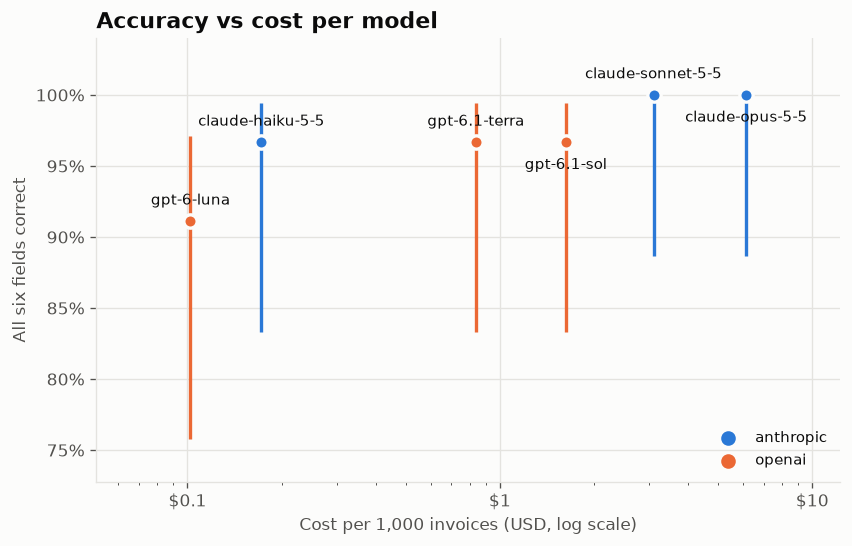

In [3]:
fig = figures.accuracy_vs_cost(final_summary)
figures.save(fig, FIGURES / "accuracy_vs_cost.svg")

## What fixing the specification did

Each run used the same models and cases. Between runs, only the field descriptions in the
schema changed, after reading the failures of the previous run.

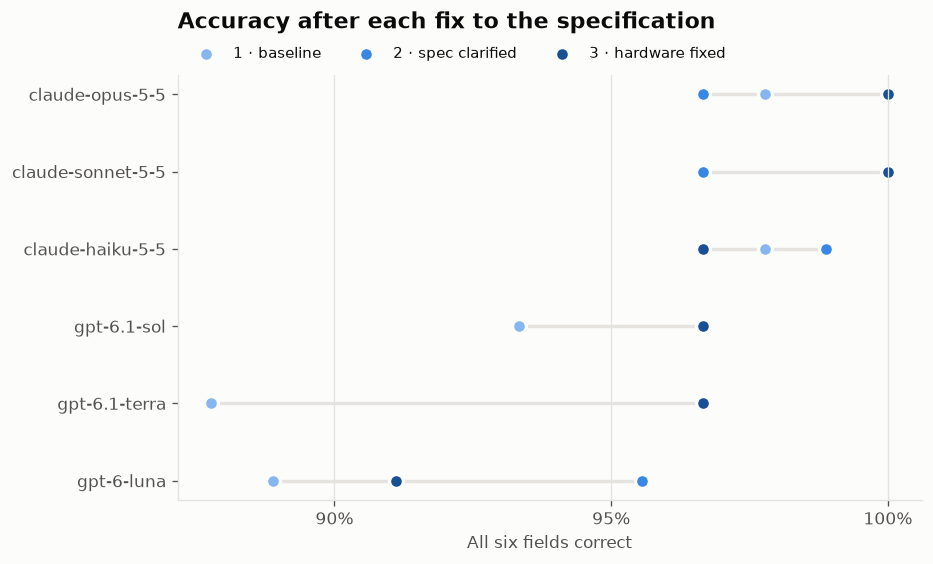

In [4]:
labelled = [(RUN_LABELS.get(run_id, run_id), summary) for run_id, summary in summaries.items()]
fig = figures.spec_iterations(labelled)
figures.save(fig, FIGURES / "spec_iterations.svg")

## Where the remaining errors are

Share of predictions in the latest run with each field wrong. Blank cells were never wrong.

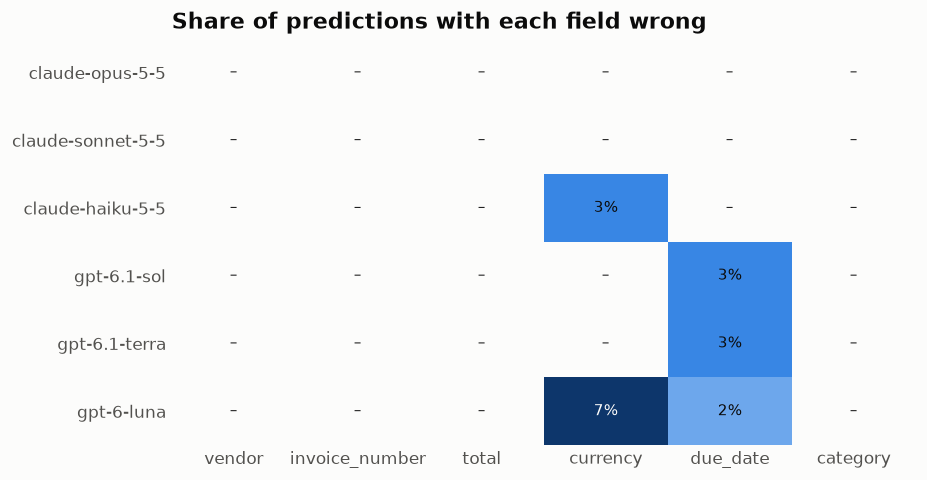

In [5]:
fig = figures.field_errors(analysis.field_error_rates(final))
figures.save(fig, FIGURES / "field_errors.svg")

## Latency

Wall-clock seconds per extraction, including thinking and any repair call. Benchmark calls ran
eight at a time, so absolute numbers include some queueing; compare models, not raw values.

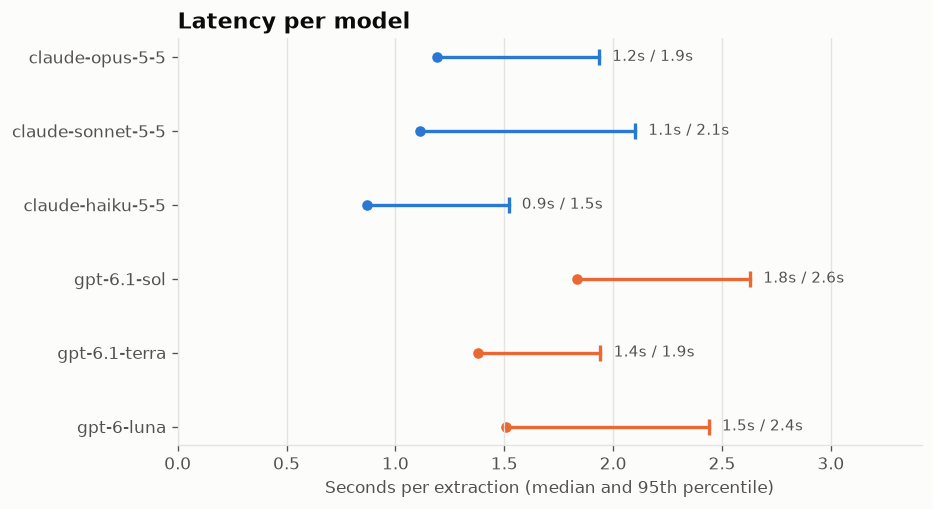

In [6]:
fig = figures.latency(final_summary)
figures.save(fig, FIGURES / "latency.svg")

## Error rate by case tag

Share of predictions not fully correct, by what makes a case hard. A case with several tags
counts under each, and most tags cover only a few cases, so read these as pointers to failures
worth inspecting, not as rates to compare.

In [7]:
analysis.tag_error_rates(final, cases).map("{:.0%}".format)

model,claude-opus-5-5,claude-sonnet-5-5,claude-haiku-5-5,gpt-6.1-sol,gpt-6.1-terra,gpt-6-luna
tag,,,,,,
ambiguous_category,0%,0%,0%,0%,0%,0%
distractor_amounts,0%,0%,7%,0%,0%,7%
distractor_documents,0%,0%,0%,0%,0%,0%
easy,0%,0%,0%,0%,0%,0%
informal,0%,0%,0%,0%,0%,0%
locale_formats,0%,0%,11%,33%,33%,22%
no_due_date,0%,0%,0%,0%,0%,11%
no_invoice_number,0%,0%,0%,0%,0%,0%
noisy_text,0%,0%,0%,100%,100%,67%


## Every remaining failure

The latest run's wrong fields, with the expected value and what the model answered. Reading
these is how the specification fixes above were found.

In [8]:
display(analysis.failures(final, cases).drop(columns="error").reset_index(drop=True))

,case_id,field,model,repeat,expected,got
0,inv-006,currency,gpt-6-luna,1,GBP,other
1,inv-006,currency,gpt-6-luna,2,GBP,other
2,inv-006,currency,gpt-6-luna,3,GBP,other
3,inv-007,currency,gpt-6-luna,1,JPY,other
4,inv-010,currency,claude-haiku-5-5,1,CAD,other
5,inv-010,currency,claude-haiku-5-5,3,CAD,other
6,inv-013,currency,claude-haiku-5-5,1,EUR,other
7,inv-017,due_date,gpt-6-luna,1,2026-10-11,1011-10-11
8,inv-017,due_date,gpt-6-luna,3,2026-10-11,1011-10-11
9,inv-017,due_date,gpt-6.1-sol,1,2026-10-11,1010-11-20


## Limits of this benchmark

- **30 cases.** Intervals are wide; differences of a few percentage points are not evidence.
- **The specification was tuned on the same cases it is scored on.** The fixes were general
  rules, but a held-out test set is the proper guard (Phase 7).
- **One task, one prompt.** Results say which models suit *this* extraction, not which is better
  in general.